# Photometry for free: absolute magnitude and phase curve from the astrometric archive

**Question.** Almost every astrometric report also carries a magnitude. Taken together, what do
those magnitudes say about an asteroid's intrinsic brightness, its **absolute magnitude H**
(and hence its size), and about how it dims as the Sun-asteroid-observer **phase angle**
grows? And how far can we trust them?

**Test case: (1036) Ganymed**, the largest near-Earth asteroid (~38 km, an Amor). Its orbit
takes it from opposition, at a phase angle of a few degrees, to close Earth passes at phase
angles above 50°, so the archive samples nearly its whole phase curve.

A PyRoOrb fit computes the observer-asteroid-Sun geometry for every observation. It converts
each magnitude to V (band corrections) and estimates H the find_orb way: a weighted mean under
the standard H,G phase law with **G fixed at 0.15**. Here we check that H against the MPC and then
go one step further, **fitting G as well**. Along the way we meet two traps: comparing an H with
one computed under a different G, and mixing surveys in a phase-curve fit.

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import pyroorb

pyroorb.load_settings()       # the .env settings file (data folders), before the first fit

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.0


In [2]:
desig = "1036"
obs = pyroorb.fetch_observations(desig)
fit = pyroorb.fit_orbit(obs, designation=desig)
H, sigma_H = fit.absolute_magnitude()
print(f"{len(obs)} observations, {fit.n_magnitudes()} magnitudes used for H")
print(f"PyRoOrb H = {H:.2f} +- {sigma_H:.3f}  (G fixed at {fit.slope_parameter()})")

13321 observations, 11627 magnitudes used for H
PyRoOrb H = 9.21 +- 0.001  (G fixed at 0.15)


## Check 1: H against the MPC, like for like

An H means nothing without the G it was computed under. With a steeper or shallower phase law,
the same observations extrapolate to zero phase angle at a different brightness. So we ask the
MPC for its own H **and** the G it used. JPL's SBDB, for comparison, lists an H and a G side by
side, but each carries its own reference.

In [3]:
import json, urllib.request

req = urllib.request.Request("https://data.minorplanetcenter.net/api/get-orb", method="GET",
                             data=json.dumps({"desig": desig}).encode(),
                             headers={"Content-Type": "application/json"})
mpc = json.load(urllib.request.urlopen(req, timeout=60))[0]["mpc_orb"][0]["magnitude_data"]
sbdb = json.load(urllib.request.urlopen(
    f"https://ssd-api.jpl.nasa.gov/sbdb.api?sstr={desig}&phys-par=1", timeout=60))["phys_par"]
jpl = {p["name"]: (float(p["value"]), p["ref"]) for p in sbdb if p["name"] in ("H", "G")}

print(f"PyRoOrb : H = {H:.2f} with G = 0.15")
print(f"MPC     : H = {mpc['H']:.2f} with G = {mpc['G']:.2f}   (same G: a like-for-like comparison)")
print(f"JPL SBDB: H = {jpl['H'][0]:.2f} (ref {jpl['H'][1]}),  G = {jpl['G'][0]:.2f} (ref {jpl['G'][1]})")

PyRoOrb : H = 9.21 with G = 0.15
MPC     : H = 9.17 with G = 0.15   (same G: a like-for-like comparison)
JPL SBDB: H = 9.17 (ref E2026E92),  G = 0.30 (ref PDS3 (MPC 17260))


PyRoOrb and the MPC agree to a few hundredths of a magnitude. They are two weighted means of the
same archive under the same G = 0.15.

SBDB's H is the MPC's value (its reference is an MPC orbit circular), so it was also computed with
G = 0.15. SBDB's G = 0.30 comes from a separate, older publication. **The two were never fitted
together.** Drawing the curve "H = 9.17, G = 0.30" plots a phase law that neither source derived.

## The phase curve

`fit.magnitude_residuals()` gives, per observation, the phase angle α and
dMag = observed − computed. The **reduced magnitude**, the brightness the asteroid would have at
1 au from both the Sun and the observer, is then

$$V(1,1,\alpha) = H + \mathrm{dMag} - 2.5\log_{10}\Phi_{G=0.15}(\alpha),$$

with Φ the Bowell et al. (1989) H,G phase function, written out below in a few lines.

In [4]:
import pandas as pd

def phi12(alpha_deg):
    t = np.tan(np.radians(alpha_deg) / 2)
    return np.exp(-3.33 * t**0.63), np.exp(-1.87 * t**1.22)

def hg_mag(alpha_deg, H, G):
    """Reduced magnitude V(1,1,alpha) of the H,G phase law."""
    p1, p2 = phi12(alpha_deg)
    return H - 2.5 * np.log10((1 - G) * p1 + G * p2)

mags = pd.DataFrame([m for m in fit.magnitude_residuals() if m["dmag"] is not None])
mags["reduced"] = H + mags.dmag + hg_mag(mags.phase_deg, 0.0, 0.15)
use = mags[mags.used & (mags.dmag.abs() < 1.5)]
print(f"{len(use)} magnitudes, phase angle {use.phase_deg.min():.1f} to {use.phase_deg.max():.1f} deg")

11480 magnitudes, phase angle 0.7 to 55.5 deg


## Fitting H and G, one survey at a time

Survey magnitudes are noisy (0.1–0.3 mag each, plus the rotational lightcurve), and some phase
angles are sampled thousands of times while others only tens of times. So we fit the H,G law to
the **median reduced magnitude in 2° phase bins**. The law is linear in its two Φ coefficients, so
this is one `lstsq` call.

The trap is **mixing surveys**. Every survey has its own photometric zero-point after band
conversion, and surveys also cover different ranges of phase angle. If one survey is offset *and*
concentrated at low or high phase, it tilts the fitted slope. So we fit each large survey on its
own, as well as all of them together.

In [5]:
def hg_fit(df, width=2, nmin=5):
    """H, G of the H,G law fitted to median reduced magnitudes in phase bins."""
    t = (df.assign(b=df.phase_deg // width).groupby("b")
         .agg(alpha=("phase_deg", "median"), R=("reduced", "median"), n=("reduced", "size")))
    t = t[t.n >= nmin]
    p1, p2 = phi12(t.alpha.values)
    flux = 10 ** (-0.4 * t.R.values)
    (a1, a2), *_ = np.linalg.lstsq(np.c_[p1, p2] / flux[:, None], np.ones(len(t)), rcond=None)
    return -2.5 * np.log10(a1 + a2), a2 / (a1 + a2), t

ATLAS = ["T05", "T08", "W68", "M22"]                 # the four ATLAS telescopes, one pipeline
groups = {"all surveys mixed": use,
          "ATLAS, o band": use[use.obscode.isin(ATLAS) & use.band.str.endswith("o")],
          "ATLAS, c band": use[use.obscode.isin(ATLAS) & use.band.str.endswith("c")],
          "TESS (C57)": use[use.obscode == "C57"]}

print(f"{'':20s} {'n':>6s}  {'phase (deg)':>12s}  {'offset':>7s}  {'H':>5s}  {'G':>5s}  {'H at G=0.15':>11s}")
fits = {}
for name, df in groups.items():
    Hf, Gf, t = hg_fit(df)
    H15 = np.median(df.reduced - hg_mag(df.phase_deg, 0.0, 0.15))
    fits[name] = (Hf, Gf, t)
    print(f"{name:20s} {len(df):6d}  {df.phase_deg.min():5.1f}-{df.phase_deg.max():5.1f}  "
          f"{df.dmag.median():+7.2f}  {Hf:5.2f}  {Gf:5.2f}  {H15:11.2f}")

                          n   phase (deg)   offset      H      G  H at G=0.15
all surveys mixed     11480    0.7- 55.5    +0.08   9.62   0.46         9.30
ATLAS, o band          2099    1.8- 50.3    +0.00   9.46   0.39         9.21
ATLAS, c band           551    4.0- 34.6    +0.00   9.33   0.26         9.22
TESS (C57)             1417    1.9- 14.3    +0.36   9.64   0.22         9.57


**ATLAS on its own** (one pipeline, four telescopes, two filters, phase angles from 2° to 50°)
gives H ≈ 9.3–9.5 with G ≈ 0.26–0.39: the two filters agree to about 0.1 mag in H, and their
G values bracket the published 0.30.

**All surveys mixed** gives a much shallower curve and a fainter H. The culprit is TESS. Its
magnitudes run about a third of a magnitude faint after band conversion. Ganymed was also observed
by TESS only near opposition, so TESS supplies a large share of the lowest-phase points. Faint
points at low phase flatten the opposition end of the curve, which raises G and drags H fainter.

The **H at G = 0.15** column puts each estimate on the MPC's footing. ATLAS lands within ~0.05 mag
of the MPC value, and TESS sits ~0.4 mag fainter.

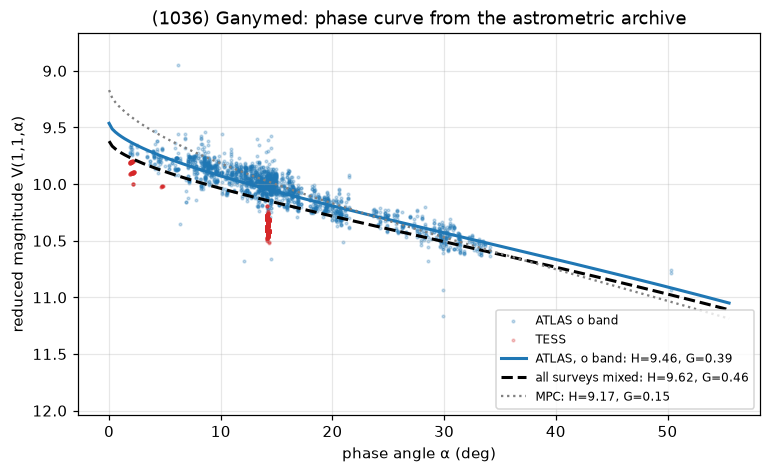

In [6]:
alpha = np.linspace(0, use.phase_deg.max(), 200)
atl, tess = groups["ATLAS, o band"], groups["TESS (C57)"]
fig, ax = plt.subplots()
ax.scatter(atl.phase_deg, atl.reduced, s=3, alpha=0.25, color="C0", label="ATLAS o band")
ax.scatter(tess.phase_deg, tess.reduced, s=3, alpha=0.25, color="C3", label="TESS")
for name, color, ls in [("ATLAS, o band", "C0", "-"), ("all surveys mixed", "k", "--")]:
    Hf, Gf, t = fits[name]
    ax.plot(alpha, hg_mag(alpha, Hf, Gf), color=color, ls=ls, lw=2,
            label=f"{name}: H={Hf:.2f}, G={Gf:.2f}")
ax.plot(alpha, hg_mag(alpha, mpc["H"], mpc["G"]), color="0.5", ls=":", lw=1.5,
        label=f"MPC: H={mpc['H']:.2f}, G={mpc['G']:.2f}")
ax.invert_yaxis()
ax.set_ylim(use.reduced.quantile(0.995) + 0.3, min(fits["ATLAS, o band"][0], mpc["H"]) - 0.5)
ax.set_xlabel("phase angle α (deg)")
ax.set_ylabel("reduced magnitude V(1,1,α)")
ax.set_title(f"({desig}) Ganymed: phase curve from the astrometric archive")
ax.legend(loc="lower right", fontsize=8)
plt.show()

## How consistent are the surveys?

The residual dMag of each observation, grouped by observatory, shows each station's
*systematic* photometric offset after PyRoOrb's band-to-V conversion. These are the
differences between catalogues, filters and reduction pipelines that make archival H values
uncertain at the few-tenths-of-a-magnitude level. The station names come from the MPC
observatory-code table that ships with PyRoOrb.

,station,band,n,offset
obscode,,,,
C57,TESS,G,1417,0.36
H21,"Astronomical Research Observatory, Wes",V,896,0.16
T08,"ATLAS-MLO, Mauna Loa",Ao,821,0.01
T05,"ATLAS-HKO, Haleakala",Ao,794,-0.00
W68,"ATLAS Chile, Rio Hurtado",Ao,785,-0.01
C40,Kuban State University Astrophysical O,G,749,0.04
D04,Krasnodar,G,448,0.09
M22,"ATLAS South Africa, Sutherland",Ao,398,-0.00
703,University of Arizona Catalina Sky Sur,G,309,0.13


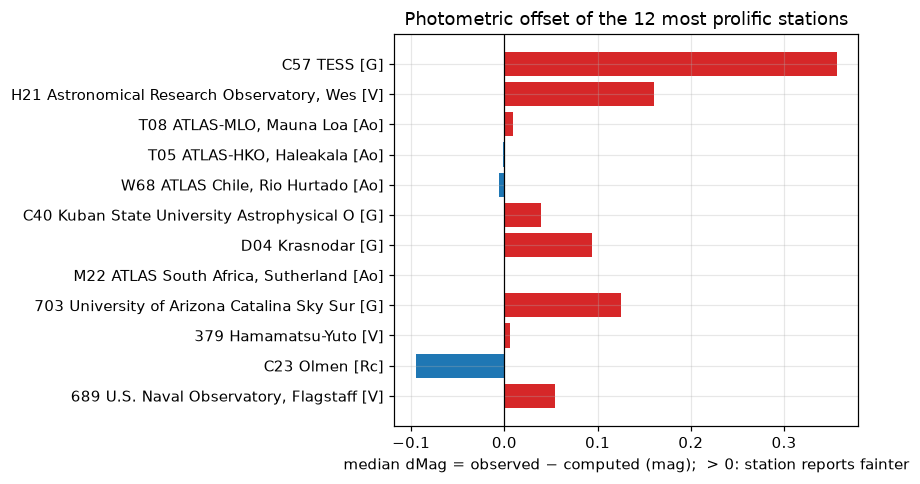

In [7]:
from importlib.resources import files
names = {}
for line in (files("pyroorb") / "package_data" / "ObsCodes.htm").read_text().splitlines():
    if len(line) > 30 and line[3] == " ":
        names[line[:3]] = line[30:].strip()

by_station = (mags[mags.used].groupby("obscode")
              .agg(n=("dmag", "size"), offset=("dmag", "median"),
                   band=("band", lambda s: s.value_counts().index[0]))
              .sort_values("n", ascending=False).head(12))
by_station["station"] = [names.get(c, "?")[:38] for c in by_station.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
lbl = [f"{c} {s} [{b}]" for c, s, b in zip(by_station.index, by_station.station, by_station.band)]
ax.barh(lbl[::-1], by_station.offset[::-1], color=np.where(by_station.offset[::-1] > 0, "C3", "C0"))
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("median dMag = observed − computed (mag);  > 0: station reports fainter")
ax.set_title("Photometric offset of the 12 most prolific stations")
fig.tight_layout()
by_station[["station", "band", "n", "offset"]].round(2)

## Takeaways

* A plain orbit fit already yields an absolute magnitude, and PyRoOrb's (G = 0.15) agrees with
  the MPC's, computed under the same G, to a few hundredths of a magnitude.
* **Compare H values only under the same G.** Catalogue H and G often come from different sources.
  SBDB pairs the MPC's G = 0.15 H with a G = 0.30 from elsewhere, a combination no one fitted.
* With a few lines more, the same archive gives the **phase curve and G**. Fitted to a single,
  homogeneous survey (ATLAS), Ganymed comes out at H ≈ 9.3–9.5, G ≈ 0.26–0.39, bracketing the
  published G = 0.30.
* **Don't mix surveys in a phase-curve fit.** One offset survey concentrated at low phase (here
  TESS, ~0.4 mag faint and observing only near opposition) bends the fitted curve to G ≈ 0.45 and
  an H ~0.2 mag too faint.
* TESS is a space telescope with a very broad red bandpass, and its magnitudes arrive coded as
  band G. A generic band-to-V shift evidently does not fit it.

**Caveats.** Archival survey magnitudes are not calibrated photometry. They mix catalogues and
filters, sample random rotational phases of the lightcurve, and come with no per-observation
uncertainty. Treat an archival H as good to about 0.1–0.2 mag, not to the hundredths a formal
sigma suggests. The H,G fits here are a demonstration of the method, not a calibrated measurement.